# Critical-Ray-Path Refractometer Prism Example

This notebook demonstrates the `from_critical_ray_path` constructor for `RefractometerPrism`.

The key idea: **all prism dimensions are derived from just two physical inputs** — the critical angle
at the measuring surface (set by `n_prism` and `n_target`) and the desired total ray path
length `L` inside the prism. No separate height or base parameters are needed.

We build a simulation where a ray entering perpendicular to the entrance face *E* travels
straight to the measuring surface *M*, hits it at exactly the critical angle, reflects via TIR,
and exits perpendicular to the exit face *X*.

## Physics Background

### Prism geometry

```
    V3-----------V2    ← Edge 2: Measuring Surface (M) — sample contact / TIR boundary
     \           /
   E  \         / X   ← Edge 1: Exit Face (X)
       \       /
       V0-----V1      ← Edge 0: Base (B)

   Edge 3 (V3→V0): Entrance Face (E)
```

The prism is a symmetric trapezoid.  All four dimensions — height $h$, face lengths $E = X$,
measuring surface $M$, and base $B$ — follow from just $\theta_c$ and $L$:

$$\theta_c = \arcsin\!\left(\frac{n_{\text{target}}}{n_{\text{prism}}}\right)$$

$$h = L\cos\theta_c, \quad E = \frac{h}{\sin\theta_c}, \quad M = \frac{L}{\sin\theta_c}, \quad B = M - 2b$$

where $b = \sqrt{E^2 - h^2}$ is the horizontal overhang of each slanted side.

### Validity constraint

The base $B$ is positive only when $\theta_c > 45°$.  For typical refractometer glass
($n_{\text{prism}} \approx 1.72$, $n_{\text{target}} \approx 1.33$) we get $\theta_c \approx 50.7°$,
so the constraint is naturally satisfied.

### Numerical example ($n_{\text{prism}}=1.72$, $n_{\text{target}}=1.33$, $L=20$)

| Quantity | Value |
|---|---|
| $\theta_c$ | $50.66°$ |
| $h$ | $12.69$ |
| $E = X$ | $16.42$ |
| $M$ | $25.88$ |
| $B$ | $5.04$ |

### The design ray path

A ray entering perpendicular to *E* at its midpoint travels at angle $\theta_c$ relative to
the vertical.  It hits *M* (the horizontal top edge) at exactly the critical angle
$\theta_c$ (measured from the surface normal).  After TIR it exits perpendicular to *X*.
Because it enters and exits perpendicular to the faces, there is **no refraction** at
those surfaces — only at *M*.

This geometry means the instrument is tuned to measure samples with $n \approx n_{\text{target}}$.
Samples with $n < n_{\text{target}}$ lower $\theta_c$, so the same ray undergoes TIR.
Samples with $n > n_{\text{target}}$ raise $\theta_c$, so the ray is transmitted through *M*.

## Imports

In [1]:
# cell 1
from IPython.display import display, HTML
import math
from dataclasses import dataclass, field
from uuid import uuid4
from typing import Dict, Any, Tuple
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# cell 2
# core
from ray_tracing_shapely.core.scene import Scene
from ray_tracing_shapely.core.scene_objs.light_source.angle_source import AngleSource
from ray_tracing_shapely.core.scene_objs.light_source.single_ray import SingleRay
from ray_tracing_shapely.core.simulator import Simulator
from ray_tracing_shapely.core.svg_renderer import SVGRenderer
from ray_tracing_shapely.core.scene_objs.glass.glass import Glass
from ray_tracing_shapely.core.scene_objs.blocker import Blocker
from ray_tracing_shapely.core.scene_objs.other import Detector


# prisms
from ray_tracing_shapely.optical_elements.prisms import (
    RefractometerPrism,
    tir_utils,
)
from ray_tracing_shapely.optical_elements.prisms import refractometer_prism_from_critical_ray_path

# analysis
from ray_tracing_shapely.analysis import (
    SimulationResult,
    describe_simulation_result,
    describe_prism,
)

## Helper dataclass

We use the same `ExampleReturn` container as the Abbe refractometer notebook so that
cells further down can work uniformly with any example result.

In [4]:
# cell 3
@dataclass
class ExampleReturn:
    desc: str
    renderer: SVGRenderer
    scene: Scene
    sim_results: SimulationResult
    prism: RefractometerPrism
    detector: Detector
    id: str = field(default_factory=lambda: str(uuid4()))

In [5]:
# cell 4
# optical_parmameters 
ip_n_prism =1.72          # prism glass (e.g. N-SF11)
ip_n_target= 1.33         # design target: sets the prism geometry (e.g. water)
ip_n_sample =1.6         # at the design point
ip_ray_path_length = 20.0
ip_sample_thickness =  15.0
ip_sample_padding= 7.5


## Default scene parameters

In [6]:
# cell 4
crp_scene_setup: Dict[str, Any] = {
    'min_brightness_exp': 3,   # increase to see more secondary reflections
    'ray_density': 36,
    'color_mode': 'linear',
    'mode': 'rays',
    'show_ray_arrows': True,
    'grazing_polarization_ratio_threshold': 1.4,
}

crp_light_source_setup: Dict[str, Any] = {
    'emission_angle': 60,   # half-angle of the fan in degrees
    'symmetric': True,
    'brightness': 1.0,
    'label_pre': 'crp_source_',
    'source_standoff': 2.0,  # distance of source from midpoint of E (outside the prism)
}

## Main example function

`example_critical_ray_path_prism` is a self-contained optical simulation builder.  All
important physical and scene parameters are exposed as arguments with sensible defaults.

**Key parameters:**

| Parameter | Role |
|---|---|
| `n_prism` | Refractive index of the prism glass |
| `n_target` | Sample index used to **design** the prism geometry |
| `n_sample` | Sample index actually placed on the measuring surface (can differ from `n_target`) |
| `ray_path_length` | Total ray path length $L$ inside the prism (mm) |
| `emission_angle` | Half-angle of the ray fan entering the entrance face (degrees) |

Setting `n_sample == n_target` places the system exactly at the TIR boundary.
Sweeping `n_sample` around `n_target` shows how the shadow line moves.

In [7]:
# cell 5
def example_critical_ray_path_prism(
    n_prism: float = 1.72,          # prism glass (e.g. N-SF11)
    n_target: float = 1.33,         # design target: sets the prism geometry (e.g. water)
    n_sample: float = 1.33,         # sample actually on the measuring surface
    ray_path_length: float = 20.0,  # total internal path length L (mm)
    prism_position: Tuple[float, float] = (0.0, 0.0),
    prism_rotation: float = 0.0,    # rotation of the whole prism in degrees
    dic_scene_setup: Dict[str, Any] = crp_scene_setup,
    light_source_setup: Dict[str, Any] = crp_light_source_setup,
    detector_offset_from_exit_face: float = 5.0,  # distance of the detector from the exit face along x (mm)
    sample_thickness: float = 15.0,  # thickness of the sample layer on the measuring surface (mm)
    sample_padding: float = 5.0,    # padding around the sample (mm)
    use_blocker_around_sample: bool = False,  # whether to add blockers around the sample to isolate it
    verbose: bool = False,
) -> ExampleReturn:
    """
    Build a self-contained ray-tracing simulation around the from_critical_ray_path
    constructor.

    The prism geometry is derived entirely from n_prism, n_target, and ray_path_length.
    The sample placed on the measuring surface is n_sample (default == n_target, i.e.
    right at the TIR boundary).

    Light enters through the entrance face E as a fan of rays (AngleSource) centred
    on the perpendicular-to-E direction.  Rays near the axis hit the measuring surface
    at the critical angle; the fan width lets you see what happens slightly above and
    below theta_c.
    """
    # ------------------------------------------------------------------
    # 1. Scene
    # ------------------------------------------------------------------
    scene = Scene()
    scene.ray_density = dic_scene_setup['ray_density']
    scene.color_mode = dic_scene_setup['color_mode']
    scene.mode = dic_scene_setup['mode']
    scene.show_ray_arrows = dic_scene_setup['show_ray_arrows']
    scene.min_brightness_exp = dic_scene_setup['min_brightness_exp']
    scene.grazing_polarization_ratio_threshold = dic_scene_setup['grazing_polarization_ratio_threshold']

    # ------------------------------------------------------------------
    # 2. Prism — geometry derived from n_prism, n_target, ray_path_length
    # ------------------------------------------------------------------
    prism = RefractometerPrism.from_critical_ray_path(
        scene=scene,
        n_prism=n_prism,
        n_target=n_target,
        ray_path_length=ray_path_length,
        position=prism_position,
        rotation=prism_rotation,
    )
    prism.name = 'refractometer_prism'

    # Override refIndex to the sample being measured (not the design target)
    # The prism glass refIndex is n_prism; we represent the sample as a thin
    # glass layer on the measuring surface by setting the prism's refIndex to n_prism.
    # The sample interacts via the TIR condition at M, which depends on n_sample.
    # In this single-object model we cannot add a separate sample layer, so we
    # annotate n_sample on the prism for inspection and rely on the fact that the
    # simulator uses the prism glass index (n_prism) inside and air (n=1) outside.
    # To explore different samples, change n_sample and observe where TIR occurs.
    #
    # NOTE: In a full two-object scene you would add a glass slab for the sample
    # above the measuring surface with refIndex = n_sample.
    prism.refIndex = n_prism
    prism.n_sample_on_surface = n_sample   # informational attribute

    scene.add_object(prism)
    scene.auto_label_all_glass_cardinal()   # apply cardinal (N/S/E/W) labels
    
    # Read V3 (index 3) ,V0 (index 0), ..., from the prism path (scene coords)
    v0 = prism.path[0]   # {'x': ..., 'y': ..., 'arc': False}
    v3 = prism.path[3]
    v2 = prism.path[2]
    v1 = prism.path[1]

    # ------------------------------------------------------------------
    # 3a. Compute the source position and direction
    #
    # The entrance face E is edge 3: V3 → V0.
    # Vertices (before rotation/translation):
    #   V0 = (-half_B, 0)     V3 = (-half_M, h)
    # After from_critical_ray_path the path is already in scene coords.
    #
    # We read V0 and V3 from prism.path and compute:
    #   midpoint_E = (V3 + V0) / 2
    #   inward_normal_E = (sin(theta_c), cos(theta_c))  [in default orientation]
    # then place the source just outside E along the outward normal.
    # ------------------------------------------------------------------
    dims = tir_utils.trapezoid_from_critical_ray_path(n_target, n_prism, ray_path_length)
    theta_c_rad = math.radians(dims['theta_c_deg'])


    if verbose:
        print("Prism top vertices in scene coordinates:")
        print(f"V0: ({v0['x']:.3f}, {v0['y']:.3f})")
        print(f"V3: ({v3['x']:.3f}, {v3['y']:.3f})")

    mid_x = (v0['x'] + v3['x']) / 2.0
    mid_y = (v0['y'] + v3['y']) / 2.0

    # Inward normal of E for rotation=0: (sin(theta_c), cos(theta_c))
    # For a rotated prism we would need to rotate this vector by prism_rotation,
    # but for this educational example we keep rotation=0.
    if prism_rotation != 0.0:
        rot_rad = math.radians(prism_rotation)
        nx = math.sin(theta_c_rad) * math.cos(rot_rad) - math.cos(theta_c_rad) * math.sin(rot_rad)
        ny = math.sin(theta_c_rad) * math.sin(rot_rad) + math.cos(theta_c_rad) * math.cos(rot_rad)
    else:
        nx = math.sin(theta_c_rad)   # inward normal x-component
        ny = math.cos(theta_c_rad)   # inward normal y-component

    standoff = light_source_setup['source_standoff']

    # Source sits outside the prism, displaced along the outward normal
    src_x = mid_x - standoff * nx
    src_y = mid_y - standoff * ny

    # Reference point for the AngleSource direction: one unit inward from source
    ref_x = src_x + nx
    ref_y = src_y + ny

    if verbose:
        print(f"theta_c = {dims['theta_c_deg']:.3f} deg")
        print(f"Prism dims: h={dims['h']:.3f}, E={dims['E']:.3f}, M={dims['M']:.3f}, B={dims['B']:.3f}")
        print(f"Source position: ({src_x:.3f}, {src_y:.3f})")
        print(f"Inward normal: ({nx:.4f}, {ny:.4f})")

    # ------------------------------------------------------------------
    # 3b. Compute the position of the detector 
    #
    # The exit face X is edge 3: V1 → V2.
    # power will have sign positive when it crosses from left to right going from p1 to p2
    # -----------------------------------------------------------------------

    det = Detector(scene,{
        'twoSided': False,  # one-sided: counts the light arriving at its front (C-DET-01)
        'p1': {'x': v1['x'] + detector_offset_from_exit_face, 'y': v1['y']},
        'p2': {'x': v2['x'] + detector_offset_from_exit_face, 'y': v2['y']},
        'irradMap' : True,
        'binSize': 0.1,
    })
    scene.add_object(det)
    # ------------------------------------------------------------------
    # 4. Target medium — thin layer on the measuring surface with n_sample
    # ------------------------------------------------------------------
    
    # Create medium in between prisms
    medium = Glass(scene)
    medium.path = [
        {'x': v3['x'] - sample_padding, 'y': v3['y'], 'arc': False},
        {'x': v2['x'] + sample_padding, 'y': v2['y'], 'arc': False},
        {'x': v2['x'] + sample_padding, 'y': v2['y'] + sample_thickness, 'arc': False},
        {'x': v3['x'] - sample_padding, 'y': v3['y'] + sample_thickness, 'arc': False}
    ]
    medium.not_done = False
    medium.refIndex = n_sample
    medium.name = "sample_medium"
    
    scene.add_object(medium)

    if use_blocker_around_sample:
        left_blocker = Blocker(scene,{
            'p1': {'x': v3['x'] - sample_padding, 'y': v3['y']},
            'p2': {'x': v3['x'] - sample_padding, 'y': v3['y'] + sample_thickness},
            'filter': False
        })
        top_blocker = Blocker(scene,{
            'p1': {'x': v3['x'] - sample_padding, 'y': v3['y'] + sample_thickness},
            'p2': {'x': v2['x'] + sample_padding, 'y': v2['y'] + sample_thickness},
            'filter': False
        })
        right_blocker = Blocker(scene,{
            'p1': {'x': v2['x'] + sample_padding, 'y': v2['y']},
            'p2': {'x': v2['x'] + sample_padding, 'y': v2['y'] + sample_thickness},
            'filter': False
        })
        scene.add_object(left_blocker)
        scene.add_object(top_blocker)
        scene.add_object(right_blocker)
    
    # ------------------------------------------------------------------
    # 5. Light source — fan of rays entering E around the perpendicular
    # ------------------------------------------------------------------
    source = AngleSource(scene)
    source.p1 = {'x': src_x, 'y': src_y}
    source.p2 = {'x': ref_x, 'y': ref_y}
    source.emis_angle = light_source_setup['emission_angle']
    source.symmetric = light_source_setup['symmetric']
    source.brightness = light_source_setup['brightness']
    source.name = light_source_setup['label_pre'] + f"{n_sample:.4f}"

    scene.add_object(source)

    # ------------------------------------------------------------------
    # 6. Simulate
    # ------------------------------------------------------------------
    simulator = Simulator(scene,max_rays=20000)
    sim_res = simulator.run_with_result(name='critical_ray_path_example')

    if verbose:
        print(f"Rays traced: {simulator.processed_ray_count}")
        print(f"Segments: {len(sim_res.segments)}")

    # ------------------------------------------------------------------
    # 7. Render — viewbox sized to fit the prism with some margin
    # ------------------------------------------------------------------
    margin = ray_path_length * 0.5
    half_M = dims['M'] / 2.0
    vb_x = -half_M - margin
    vb_y = -margin
    vb_w = dims['M'] + 2 * margin
    vb_h = dims['h'] + 2 * margin

    renderer = SVGRenderer(
        width=800,
        height=600,
        viewbox=(vb_x, vb_y, vb_w, vb_h),
    )
    renderer.draw_scene(scene, sim_res.segments)

    return ExampleReturn(
        desc=f'critical_ray_path n_sample={n_sample}',
        renderer=renderer,
        scene=scene,
        sim_results=sim_res,
        prism=prism,
        detector=det,
    )

## Run the example — design point ($n_{\text{sample}} = n_{\text{target}}$)

At the design point, the central ray of the fan hits *M* at exactly $\theta_c$.  Rays
inside the fan that hit *M* above $\theta_c$ undergo TIR; rays below $\theta_c$ are
transmitted through *M* into the sample.  The shadow boundary at *M* is at the midpoint.

In [8]:
# cell 6


result_design = example_critical_ray_path_prism(
    n_prism=ip_n_prism,
    n_target=ip_n_target,
    n_sample=ip_n_sample,          # at the design point
    ray_path_length=ip_ray_path_length,
    sample_thickness=ip_sample_thickness,
    sample_padding=ip_sample_padding,
    light_source_setup = crp_light_source_setup,
    use_blocker_around_sample=True,
    verbose=True,
)
HTML(result_design.renderer.to_string())

Prism top vertices in scene coordinates:
V0: (-2.533, -6.341)
V3: (-12.932, 6.341)
theta_c = 50.647 deg
Prism dims: h=12.682, E=16.401, M=25.865, B=5.066
Source position: (-9.279, -1.268)
Inward normal: (0.7733, 0.6341)


Rays traced: 13510
Segments: 13510


In [9]:


x= np.arange(len(result_design.detector.bin_data) )
y=np.array(result_design.detector.bin_data)

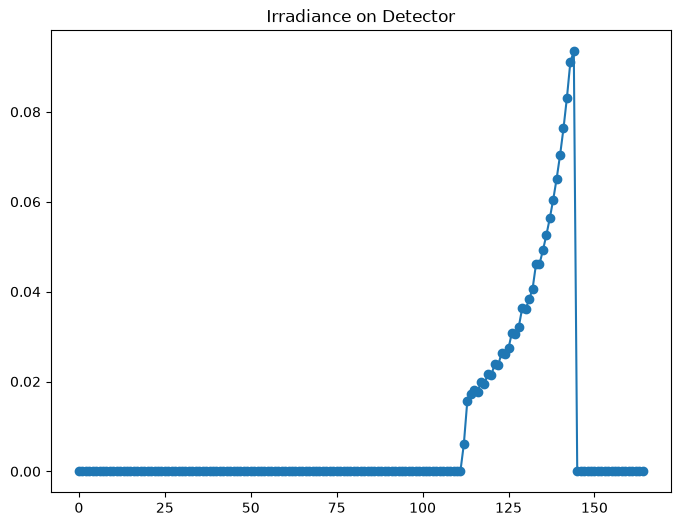

In [10]:
fig = plt.figure(figsize=(8,6))
plt.plot(x, y, marker='o')
plt.title('Irradiance on Detector')
plt.show() 

## Inspect the prism dimensions

All dimensions are derived analytically from $n_{\text{prism}}$, $n_{\text{target}}$, and $L$.

In [11]:
prism = result_design.prism

dims = tir_utils.trapezoid_from_critical_ray_path(
    n_target=prism.n_target,
    n_prism=prism.n_prism,
    ray_path_length=prism.ray_path_length,
)

print("=" * 48)
print("Refractometer prism — critical ray path design")
print("=" * 48)
print(f"  n_prism          : {prism.n_prism}")
print(f"  n_target         : {prism.n_target}")
print(f"  ray_path_length  : {prism.ray_path_length} mm")
print()
print(f"  Critical angle θc : {dims['theta_c_deg']:.3f} deg")
print(f"  Face angle        : {dims['face_angle_deg']:.3f} deg")
print()
print(f"  Prism height  h  : {dims['h']:.4f} mm")
print(f"  Entrance face E  : {dims['E']:.4f} mm")
print(f"  Measuring surf M : {dims['M']:.4f} mm")
print(f"  Base          B  : {dims['B']:.4f} mm")
print(f"  Overhang      b  : {dims['b']:.4f} mm")
print()
print(f"  Pythagorean check  M² == L² + E²: ",
      f"{abs(dims['M']**2 - prism.ray_path_length**2 - dims['E']**2):.2e} (should be ~0)")

Refractometer prism — critical ray path design
  n_prism          : 1.72
  n_target         : 1.33
  ray_path_length  : 20.0 mm

  Critical angle θc : 50.647 deg
  Face angle        : 39.353 deg

  Prism height  h  : 12.6819 mm
  Entrance face E  : 16.4006 mm
  Measuring surf M : 25.8647 mm
  Base          B  : 5.0656 mm
  Overhang      b  : 10.3995 mm

  Pythagorean check  M² == L² + E²:  0.00e+00 (should be ~0)


In [12]:
# Full prism description (edge lengths, labels, angles)
describe_prism(prism)

'\nRefractometerPrism Description\n==============================================================================\nType: RefractometerPrism\nRefractive Index: 1.720\nPosition: (0.0, 0.0)\nRotation: 0.0 degrees\n\nGeometry:\n  Measuring Surface Length: 25.86\n  Face Angle: 39.35 degrees\n  Signed Area: 196.13 (CCW vertex ordering)\n\nEdges:\n  Edge 0: Base (B) | facing South Edge (S) | length: 5.07\n  Edge 1: Exit Face (X) | facing East Edge (E) | length: 16.40\n  Edge 2: Measuring Surface (M) | facing North Edge (N) | length: 25.86\n  Edge 3: Entrance Face (E) | facing West Edge (W) | length: 16.40\n\nVertices:\n  Vertex 0: Base Left (BL) at (-2.53, -6.34) | angle: 129.4 deg\n  Vertex 1: Base Right (BR) at (2.53, -6.34) | angle: 129.4 deg\n  Vertex 2: Top Right (TR) at (12.93, 6.34) | angle: 50.6 deg\n  Vertex 3: Top Left (TL) at (-12.93, 6.34) | angle: 50.6 deg\n\nPhysics:\n  Prism Index (n_prism): 1.720\n  Sample Range: [1.230, 1.430]\n  Critical Angle Range: [45.65, 56.24] degrees\n

## Geometry validation

`validate_geometry()` checks whether the optical geometry is physically sound
(exit angles not too large, sensor coverage adequate, etc.).

In [13]:
warnings = prism.validate_geometry()
if warnings:
    for w in warnings:
        print('WARNING:', w)
else:
    print('Geometry valid — no warnings.')

Geometry valid — no warnings.


## The design ray as a SingleRay

Fire the exact design ray — entering perpendicular to *E* at its midpoint.
This ray should:
1. Enter *E* without refraction (perpendicular incidence)
2. Hit *M* at exactly $\theta_c$
3. Undergo TIR (when $n_{\text{sample}} \leq n_{\text{target}}$)
4. Exit *X* without refraction

In [14]:
def example_design_ray(
    n_prism: float = 1.72,
    n_target: float = 1.33,
    ray_path_length: float = 20.0,
    verbose: bool = False,
) -> ExampleReturn:
    """
    Fire the single design ray through the prism.

    The ray enters perpendicular to E at its midpoint, travels the full L,
    reflects off M at theta_c (TIR), and exits perpendicular to X.
    """
    scene = Scene()
    scene.ray_density = 1
    scene.color_mode = 'linear'
    scene.mode = 'rays'
    scene.show_ray_arrows = True
    scene.min_brightness_exp = 2

    prism = RefractometerPrism.from_critical_ray_path(
        scene=scene,
        n_prism=n_prism,
        n_target=n_target,
        ray_path_length=ray_path_length,
    )
    prism.name = 'design_prism'
    prism.refIndex = n_prism
    scene.add_object(prism)

    dims = tir_utils.trapezoid_from_critical_ray_path(n_target, n_prism, ray_path_length)
    theta_c_rad = math.radians(dims['theta_c_deg'])

    v0 = prism.path[0]
    v3 = prism.path[3]
    mid_x = (v0['x'] + v3['x']) / 2.0
    mid_y = (v0['y'] + v3['y']) / 2.0

    nx = math.sin(theta_c_rad)
    ny = math.cos(theta_c_rad)

    standoff = 2.0
    src_x = mid_x - standoff * nx
    src_y = mid_y - standoff * ny

    ray = SingleRay(scene)
    ray.p1 = {'x': src_x, 'y': src_y}
    ray.p2 = {'x': src_x + nx, 'y': src_y + ny}   # direction: inward normal of E
    ray.brightness = 1.0
    ray.name = 'design_ray'
    scene.add_object(ray)

    simulator = Simulator(scene)
    sim_res = simulator.run_with_result(name='design_ray')

    if verbose:
        print(f"theta_c = {dims['theta_c_deg']:.4f} deg")
        print(f"Ray source: ({src_x:.4f}, {src_y:.4f})")
        print(f"Inward normal: ({nx:.5f}, {ny:.5f})")

    margin = ray_path_length * 0.5
    half_M = dims['M'] / 2.0
    renderer = SVGRenderer(
        width=800, height=600,
        viewbox=(-half_M - margin, -margin, dims['M'] + 2 * margin, dims['h'] + 2 * margin),
    )
    renderer.draw_scene(scene, sim_res.segments)

    return ExampleReturn(
        desc='design_ray',
        renderer=renderer,
        scene=scene,
        sim_results=sim_res,
        prism=prism,
        detector=None,   # the design ray needs no detector
    )

In [15]:
result_single = example_design_ray(n_prism=1.72, n_target=1.33, ray_path_length=20.0, verbose=True)
HTML(result_single.renderer.to_string())

theta_c = 50.6472 deg
Ray source: (-9.2791, -1.2682)
Inward normal: (0.77326, 0.63409)


## Exploring different sample indices

The prism geometry is fixed (designed for $n_{\text{target}} = 1.33$).  Here we run the
fan-of-rays simulation for several sample indices to see how the shadow line moves at *M*.

| $n_{\text{sample}}$ | Compared to $n_{\text{target}}$ | Expected behaviour at *M* |
|---|---|---|
| 1.20 | much lower | $\theta_c$ lower → design ray TIRs, more light exits *X* |
| 1.33 | at design | design ray at exactly $\theta_c$ (boundary) |
| 1.45 | higher | $\theta_c$ higher → design ray transmitted through *M*, less light exits *X* |

> **Note:** In this single-glass model the simulator treats the space above *M* as air
> ($n = 1$), so TIR conditions are dominated by the glass/air boundary.  To model an
> arbitrary liquid sample accurately, add a second `Glass` slab above *M* with
> `refIndex = n_sample`.  The cells below are illustrative of the workflow.

In [16]:
sample_indices_to_explore = [1.20, 1.33, 1.45]

results = {}
for n_s in sample_indices_to_explore:
    res = example_critical_ray_path_prism(
        n_prism=1.72,
        n_target=1.33,
        n_sample=n_s,
        ray_path_length=20.0,
        dic_scene_setup={**crp_scene_setup, 'min_brightness_exp': 3},
    )
    results[n_s] = res
    print(f"n_sample = {n_s:.2f} → {len(res.sim_results.segments)} segments")

n_sample = 1.20 → 20000 segments


n_sample = 1.33 → 20000 segments


n_sample = 1.45 → 20000 segments


In [17]:
print("n_sample = 1.20 (below design — design ray TIRs at M)")
HTML(results[1.20].renderer.to_string())

n_sample = 1.20 (below design — design ray TIRs at M)


In [18]:
print("n_sample = 1.33 (at design point — shadow line at midpoint of M)")
HTML(results[1.33].renderer.to_string())

n_sample = 1.33 (at design point — shadow line at midpoint of M)


In [19]:
print("n_sample = 1.45 (above design — design ray transmitted through M)")
HTML(results[1.45].renderer.to_string())

n_sample = 1.45 (above design — design ray transmitted through M)


## Critical angle vs. sample index

Plot (numerically) how $\theta_c$ shifts as $n_{\text{sample}}$ changes.  The prism is
designed so that its face angle equals $90° - \theta_{c,\text{target}}$.  A sample with
a different $n$ shifts the critical angle, moving the shadow line on the detector.

In [20]:
import numpy as np

n_prism_val = 1.72
n_target_val = 1.33
prism_face_angle = 90.0 - math.degrees(math.asin(n_target_val / n_prism_val))

n_range = np.linspace(1.10, n_prism_val - 0.01, 200)
theta_c_values = [math.degrees(math.asin(n / n_prism_val)) for n in n_range]
exit_angle_values = [prism.exit_angle_for(n) for n in n_range]

print(f"Prism face angle (design): {prism_face_angle:.3f} deg")
print(f"At n_target={n_target_val}: theta_c = {math.degrees(math.asin(n_target_val/n_prism_val)):.3f} deg, exit_angle = {prism.exit_angle_for(n_target_val):.3f} deg")
print()

# Table of representative values
print(f"{'n_sample':>12} {'theta_c (deg)':>16} {'exit_angle (deg)':>18}")
print("-" * 50)
for n_s in [1.15, 1.20, 1.25, 1.30, 1.33, 1.36, 1.40, 1.45, 1.50, 1.55, 1.60]:
    if n_s < n_prism_val:
        tc = math.degrees(math.asin(n_s / n_prism_val))
        ea = prism.exit_angle_for(n_s)
        print(f"{n_s:>12.3f} {tc:>16.3f} {ea:>18.3f}")

Prism face angle (design): 39.353 deg
At n_target=1.33: theta_c = 50.647 deg, exit_angle = 0.000 deg

    n_sample    theta_c (deg)   exit_angle (deg)
--------------------------------------------------
       1.150           41.959             -8.688
       1.200           44.241             -6.406
       1.250           46.614             -4.033
       1.300           49.097             -1.551
       1.330           50.647              0.000
       1.360           52.251              1.604
       1.400           54.484              3.837
       1.450           57.461              6.814
       1.500           60.703             10.056
       1.550           64.311             13.664
       1.600           68.471             17.824


## Validity constraint — $\theta_c > 45°$

The `from_critical_ray_path` constructor raises `ValueError` if the critical angle is
at or below 45°, because the base $B$ would be zero or negative.

In [21]:
# Demonstrate the validity constraint
test_cases = [
    (1.72, 1.50, '→ theta_c ≈ 60.7° — valid'),
    (1.72, 1.33, '→ theta_c ≈ 50.7° — valid (design point)'),
    (1.72, 1.217, '→ theta_c ≈ 45.0° — boundary, should raise ValueError'),
    (1.72, 1.10, '→ theta_c ≈ 39.7° — invalid (theta_c < 45°)'),
    (1.33, 1.50, '→ n_prism < n_target — should raise ValueError'),
]

for n_p, n_t, label in test_cases:
    try:
        d = tir_utils.trapezoid_from_critical_ray_path(n_t, n_p, 20.0)
        tc = d['theta_c_deg']
        print(f"  n_prism={n_p}, n_target={n_t}: theta_c={tc:.2f}° — OK  {label}")
    except ValueError as e:
        print(f"  n_prism={n_p}, n_target={n_t}: ValueError: {e}  {label}")

  n_prism=1.72, n_target=1.5: theta_c=60.70° — OK  → theta_c ≈ 60.7° — valid
  n_prism=1.72, n_target=1.33: theta_c=50.65° — OK  → theta_c ≈ 50.7° — valid (design point)
  n_prism=1.72, n_target=1.217: theta_c=45.04° — OK  → theta_c ≈ 45.0° — boundary, should raise ValueError
  n_prism=1.72, n_target=1.1: ValueError: Critical angle (39.76 deg) must be > 45 deg for a valid trapezoid. Increase n_target/n_prism ratio.  → theta_c ≈ 39.7° — invalid (theta_c < 45°)
  n_prism=1.33, n_target=1.5: ValueError: TIR impossible: n_prism (1.33) must be > n_target (1.5)  → n_prism < n_target — should raise ValueError


## Summary

The `from_critical_ray_path` constructor provides a **physics-first** design workflow:

1. **Input** the refractive index of the glass and the target sample, plus the desired optical
   path length $L$ inside the prism.
2. **Derive** all four prism dimensions ($h$, $E$, $M$, $B$) from the critical angle.
3. **Guarantee** that the design ray enters perpendicular to *E*, hits *M* exactly at $\theta_c$,
   reflects via TIR, and exits perpendicular to *X* — with no refraction at the entry/exit faces.

This makes it straightforward to prototype refractometer optics for any glass/sample pair
without manual geometry calculations.